In [1]:
import torch, torchaudio
import torch.nn as nn
import numpy as np, pandas as pd
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SAMPLE_RATE = 44100
HOP_SECONDS = 0.010
HOP   = int(HOP_SECONDS * SAMPLE_RATE)
N_FFT = 2048
N_MELS = 128

class OnsetCRNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.mel   = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
        self.to_db = torchaudio.transforms.AmplitudeToDB()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(32),
            nn.MaxPool2d((2,1)),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(64),
            nn.MaxPool2d((2,1)),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(128),
        )
        feat = 128 * (N_MELS // 4)
        self.rnn = nn.GRU(feat, 128, num_layers=3, batch_first=True,
                          bidirectional=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.state_head  = nn.Linear(256, 2)
        self.onset_head  = nn.Linear(256, 1)
        self.offset_head = nn.Linear(256, 1)

    def forward(self, x):
        s = self.to_db(self.mel(x))
        s = self.cnn(s)
        B, C, M, T = s.shape
        s = s.reshape(B, C*M, T).transpose(1, 2)
        s, _ = self.rnn(s)
        s = self.drop(s)
        return self.state_head(s), self.onset_head(s).squeeze(-1), self.offset_head(s).squeeze(-1)

# ---- find the saved weights anywhere in the inputs ----
weight_files = sorted(Path("/kaggle/input").rglob("biggerCRNN_ext4_seed*.pt"))
print("device :", device)
print("weights:", [w.name for w in weight_files], "(expect 3)")

# ---- check: each weight file loads into the model without errors ----
for w in weight_files:
    m = OnsetCRNN().to(device)
    m.load_state_dict(torch.load(w, map_location=device))
    print("loaded OK:", w.name)

device : cuda
weights: ['biggerCRNN_ext4_seed0.pt', 'biggerCRNN_ext4_seed1.pt', 'biggerCRNN_ext4_seed2.pt'] (expect 3)
loaded OK: biggerCRNN_ext4_seed0.pt
loaded OK: biggerCRNN_ext4_seed1.pt
loaded OK: biggerCRNN_ext4_seed2.pt


In [2]:
TONAS = Path("/kaggle/input/datasets/alirahmatpour/vocalset-onset/tonas_upload")

def tonas_items():
    items = []
    for wav in sorted(TONAS.rglob("*.wav")):
        if wav.name.startswith("._"):                      # Mac junk
            continue
        notes = wav.parent / (wav.stem + ".notes.Corrected")
        if not notes.exists():                             # no annotation -> skip
            continue
        wf, sr = torchaudio.load(str(wav))
        wave = wf[0]
        if sr != SAMPLE_RATE:                              # safety net
            wave = torchaudio.functional.resample(wave, sr, SAMPLE_RATE)
        lines = notes.read_text(encoding="latin-1").strip().splitlines()[1:]  # skip tuning line
        onsets, offsets = [], []
        for ln in lines:
            parts = [x.strip() for x in ln.split(",")]
            if len(parts) < 2: continue
            on, dur = float(parts[0]), float(parts[1])
            onsets.append(on); offsets.append(on + dur)
        items.append({"name": wav.stem, "style": wav.parent.name, "sr": sr, "wave": wave,
                      "onsets": np.array(onsets), "offsets": np.array(offsets)})
    return items

tonas = tonas_items()

# ---- checks ----
print("TONAS clips :", len(tonas), "(expect ~72)")
print("styles      :", pd.Series([c["style"] for c in tonas]).value_counts().to_dict())
print("sample rates:", pd.Series([c["sr"] for c in tonas]).value_counts().to_dict())
print("total onsets:", sum(len(c["onsets"]) for c in tonas))
c = tonas[0]
print("example     :", c["name"], "|", round(len(c["wave"])/SAMPLE_RATE, 1), "sec |",
      len(c["onsets"]), "notes | first onsets:", np.round(c["onsets"][:5], 2))

TONAS clips : 72 (expect ~72)
styles      : {'Martinetes1': 36, 'Martinetes2': 20, 'Deblas': 16}
sample rates: {44100: 72}
total onsets: 2983
example     : 01-D_AMairena | 25.8 sec | 57 notes | first onsets: [0.22 0.65 2.18 2.57 2.9 ]


In [3]:
# ---- scoring (same peak-picking + ±20 ms tolerance as VocalSet) ----
def pick_peaks(prob, thr, min_gap=3):
    peaks = []
    for i in range(len(prob)):
        if prob[i] < thr: continue
        lo, hi = max(0, i-1), min(len(prob), i+2)
        if prob[i] == prob[lo:hi].max() and (not peaks or i-peaks[-1] >= min_gap):
            peaks.append(i)
    return set(peaks)

def event_f1(probs, true_frames, thr, tol=2):
    tp = fp = fn = 0
    for prob, t_idx in zip(probs, true_frames):
        pred = pick_peaks(prob, thr); matched = set()
        for ti in t_idx:
            hit = next((pi for pi in pred if abs(pi-ti) <= tol and pi not in matched), None)
            if hit is not None: tp += 1; matched.add(hit)
            else: fn += 1
        fp += len(pred - matched)
    p = tp/(tp+fp) if tp+fp else 0.0
    r = tp/(tp+fn) if tp+fn else 0.0
    return p, r, (2*p*r/(p+r) if p+r else 0.0)

true_on  = [(c["onsets"]  / HOP_SECONDS).astype(int) for c in tonas]
true_off = [(c["offsets"] / HOP_SECONDS).astype(int) for c in tonas]

def predict(model):
    model.eval(); ons, offs = [], []
    with torch.no_grad():
        for c in tonas:
            _, on, off = model(c["wave"].view(1, 1, -1).to(device))
            ons.append(torch.sigmoid(on)[0].cpu().numpy())
            offs.append(torch.sigmoid(off)[0].cpu().numpy())
    return ons, offs

# ---- run all 3 seeds ----
THR = 0.8                      # the threshold VocalSet validation picked (fixed, honest)
rows = []
for w in weight_files:
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(w, map_location=device))
    ons, offs = predict(model)
    p, r, f_on  = event_f1(ons,  true_on,  THR)
    _, _, f_off = event_f1(offs, true_off, THR)
    # diagnostic only: best threshold picked ON TONAS (not a fair score)
    best_t = max([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8], key=lambda t: event_f1(ons, true_on, t)[2])
    row = {"seed": w.stem[-1], "P": p, "R": r, "onset_F1": f_on, "offset_F1": f_off,
           "oracle_thr": best_t, "oracle_F1": event_f1(ons, true_on, best_t)[2]}
    # onset F1 per flamenco style
    for style in ["Deblas", "Martinetes1", "Martinetes2"]:
        idx = [i for i, c in enumerate(tonas) if c["style"] == style]
        row[style] = event_f1([ons[i] for i in idx], [true_on[i] for i in idx], THR)[2]
    rows.append(row)
    del model; torch.cuda.empty_cache()

df = pd.DataFrame(rows)
print(df.round(3).to_string(index=False))

print(f"\n=== TONAS | bigger CRNN trained on VocalSet only | thr {THR} | mean ± std ===")
for k in ["P", "R", "onset_F1", "offset_F1", "oracle_F1", "Deblas", "Martinetes1", "Martinetes2"]:
    print(f"{k:12s}: {df[k].mean():.3f} ± {df[k].std(ddof=1):.3f}")

seed     P     R  onset_F1  offset_F1  oracle_thr  oracle_F1  Deblas  Martinetes1  Martinetes2
   0 0.151 0.122     0.135      0.297         0.1      0.178   0.164        0.111        0.138
   1 0.157 0.089     0.114      0.280         0.1      0.175   0.132        0.100        0.114
   2 0.190 0.184     0.187      0.323         0.1      0.204   0.228        0.152        0.192

=== TONAS | bigger CRNN trained on VocalSet only | thr 0.8 | mean ± std ===
P           : 0.166 ± 0.021
R           : 0.132 ± 0.048
onset_F1    : 0.145 ± 0.038
offset_F1   : 0.300 ± 0.022
oracle_F1   : 0.186 ± 0.015
Deblas      : 0.175 ± 0.049
Martinetes1 : 0.121 ± 0.028
Martinetes2 : 0.148 ± 0.040


seed 0 | median offset +30 ms | F1@±20ms thr0.1: 0.178 -> after shift 0.271
seed 1 | median offset +30 ms | F1@±20ms thr0.1: 0.175 -> after shift 0.305
seed 2 | median offset +30 ms | F1@±20ms thr0.1: 0.204 -> after shift 0.306

=== onset F1 vs tolerance window (mean over 3 seeds) ===
     ±20ms  ±50ms  ±100ms
thr                      
0.1  0.186  0.435   0.579
0.8  0.145  0.409   0.616

=== timing offset (pred - true), all seeds, thr 0.1 ===
n = 12556 | median +30 ms | mean +15.9 ms | std 78 ms | within ±20ms: 20%


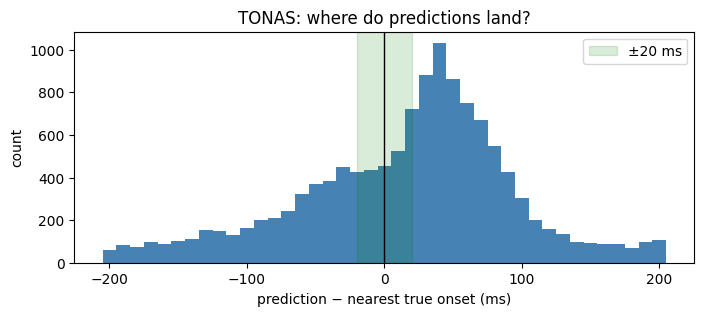

In [4]:
import matplotlib.pyplot as plt

TOLS = {"±20ms": 2, "±50ms": 5, "±100ms": 10}   # tolerance in frames (1 frame = 10 ms)
THRS = [0.8, 0.1]                               # VocalSet threshold, and TONAS-best threshold

def shifted(probs_peaks, shift):
    return [set(p + shift for p in pk) for pk in probs_peaks]

def f1_from_peaks(peaks_list, true_frames, tol):
    tp = fp = fn = 0
    for pred, t_idx in zip(peaks_list, true_frames):
        matched = set()
        for ti in t_idx:
            hit = next((pi for pi in pred if abs(pi-ti) <= tol and pi not in matched), None)
            if hit is not None: tp += 1; matched.add(hit)
            else: fn += 1
        fp += len(pred - matched)
    p = tp/(tp+fp) if tp+fp else 0.0
    r = tp/(tp+fn) if tp+fn else 0.0
    return 2*p*r/(p+r) if p+r else 0.0

rows, all_dists = [], []
for w in weight_files:
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(w, map_location=device))
    ons, _ = predict(model)
    seed = w.stem[-1]

    # 1) F1 with wider tolerance windows
    for thr in THRS:
        peaks = [pick_peaks(p, thr) for p in ons]
        row = {"seed": seed, "thr": thr}
        for name, tol in TOLS.items():
            row[name] = f1_from_peaks(peaks, true_on, tol)
        rows.append(row)

    # 2) signed distance: prediction - nearest true onset (within ±200 ms), at thr 0.1
    peaks = [pick_peaks(p, 0.1) for p in ons]
    dists = []
    for pred, t_idx in zip(peaks, true_on):
        if len(t_idx) == 0: continue
        for pi in pred:
            d = pi - t_idx[np.argmin(np.abs(t_idx - pi))]
            if abs(d) <= 20:
                dists.append(d * 10)            # frames -> ms
    all_dists += dists
    del model; torch.cuda.empty_cache()

    # 3) shift all predictions by the median offset, rescore at ±20 ms
    med = int(round(np.median(dists) / 10)) if dists else 0
    f_orig  = f1_from_peaks(peaks, true_on, 2)
    f_shift = f1_from_peaks(shifted(peaks, -med), true_on, 2)
    print(f"seed {seed} | median offset {med*10:+d} ms | F1@±20ms thr0.1: "
          f"{f_orig:.3f} -> after shift {f_shift:.3f}")

df_tol = pd.DataFrame(rows)
print("\n=== onset F1 vs tolerance window (mean over 3 seeds) ===")
print(df_tol.groupby("thr")[list(TOLS)].mean().round(3).to_string())

d = np.array(all_dists)
print(f"\n=== timing offset (pred - true), all seeds, thr 0.1 ===")
print(f"n = {len(d)} | median {np.median(d):+.0f} ms | mean {d.mean():+.1f} ms | "
      f"std {d.std():.0f} ms | within ±20ms: {np.mean(np.abs(d)<=20):.0%}")

plt.figure(figsize=(8, 3))
plt.hist(d, bins=np.arange(-205, 210, 10), color="steelblue")
plt.axvline(0, color="k", lw=1); plt.axvspan(-20, 20, color="green", alpha=0.15, label="±20 ms")
plt.xlabel("prediction − nearest true onset (ms)"); plt.ylabel("count")
plt.title("TONAS: where do predictions land?"); plt.legend(); plt.show()

In [5]:
# ===== VocalSet test set (same singers as training notebook: female4, male6) =====
V_ROOT    = Path("/kaggle/input/datasets/alirahmatpour/vocalset-onset")
V_ANNOT   = V_ROOT / "annot_ext4_upload" / "annot_ext4_upload" / "annot"
V_AUDIO   = V_ROOT / "kaggle_upload" / "kaggle_upload" / "audio"
TEST_SINGERS = {"female4", "male6"}

COLS = ["Sequence","Start","End","Duration","Type","AvgF0","MedF0","MinF0","MaxF0",
        "StdF0","AvgF0_inSTD","EstMIDI","GTNote","GTFreq","GTMIDI","Lyric",
        "GTDurName","GTDur","IntPrev","IntNext","Extra"]

def read_annot(csv_path):
    a = pd.read_csv(csv_path, skiprows=17, header=None, names=COLS)
    return a[["Start","End","Type"]].dropna(subset=["Start","End","Type"])

csv_lookup = {p.stem: p for p in V_ANNOT.rglob("*.csv")}
vs_test, dropped = [], 0
for wav in sorted(V_AUDIO.rglob("*.wav")):
    singer = wav.parts[wav.parts.index("audio") + 1]
    if singer not in TEST_SINGERS or wav.stem not in csv_lookup:
        continue
    wf, sr = torchaudio.load(str(wav))
    ann = read_annot(csv_lookup[wav.stem])
    if not len(ann) or abs(ann["End"].max()/(wf.shape[1]/sr) - 1.0) > 0.1:   # same clean filter
        dropped += 1; continue
    snd = ann[ann["Type"] == "Sound"]
    nfr = 1 + wf.shape[1] // HOP
    on_f = sorted({int(s/HOP_SECONDS) for s in snd["Start"] if int(s/HOP_SECONDS) < nfr})
    vs_test.append({"wave": wf[0], "on_frames": np.array(on_f),
                    "sex": "female" if singer.startswith("female") else "male"})

print("VocalSet test recs:", len(vs_test), "| dropped:", dropped, "(expect 252: 143 male / 109 female)")
vs_true = [c["on_frames"] for c in vs_test]

# ===== score all 3 seeds at 3 tolerances (thr 0.8, same as TONAS) =====
rows, vs_dists = [], []
for w in weight_files:
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(w, map_location=device)); model.eval()
    ons = []
    with torch.no_grad():
        for c in vs_test:
            _, on, _ = model(c["wave"].view(1, 1, -1).to(device))
            ons.append(torch.sigmoid(on)[0].cpu().numpy())
    peaks = [pick_peaks(p, 0.8) for p in ons]
    row = {"seed": w.stem[-1]}
    for name, tol in TOLS.items():
        row[name] = f1_from_peaks(peaks, vs_true, tol)
    rows.append(row)
    # timing offset on VocalSet too (for comparison with TONAS)
    for pred, t_idx in zip(peaks, vs_true):
        if len(t_idx) == 0: continue
        for pi in pred:
            d = pi - t_idx[np.argmin(np.abs(t_idx - pi))]
            if abs(d) <= 20: vs_dists.append(d * 10)
    del model; torch.cuda.empty_cache()

df_vs = pd.DataFrame(rows)
print("\n=== onset F1, thr 0.8, mean ± std over 3 seeds ===")
tonas_08 = df_tol[df_tol["thr"] == 0.8]
for name in TOLS:
    print(f"{name:7s} | VocalSet {df_vs[name].mean():.3f} ± {df_vs[name].std(ddof=1):.3f} "
          f"| TONAS {tonas_08[name].mean():.3f} ± {tonas_08[name].std(ddof=1):.3f}")

vd = np.array(vs_dists)
print(f"\nVocalSet timing offset: median {np.median(vd):+.0f} ms | std {vd.std():.0f} ms "
      f"| within ±20ms: {np.mean(np.abs(vd)<=20):.0%}")
print(f"TONAS    timing offset: median {np.median(d):+.0f} ms | std {d.std():.0f} ms "
      f"| within ±20ms: {np.mean(np.abs(d)<=20):.0%}")

VocalSet test recs: 252 | dropped: 0 (expect 252: 143 male / 109 female)

=== onset F1, thr 0.8, mean ± std over 3 seeds ===
±20ms   | VocalSet 0.834 ± 0.014 | TONAS 0.145 ± 0.038
±50ms   | VocalSet 0.926 ± 0.006 | TONAS 0.409 ± 0.043
±100ms  | VocalSet 0.947 ± 0.004 | TONAS 0.616 ± 0.046

VocalSet timing offset: median +0 ms | std 33 ms | within ±20ms: 85%
TONAS    timing offset: median -41 ms | std 0 ms | within ±20ms: 0%


In [6]:
# ===== 1) how many onsets have NO loudness attack? (TONAS vs VocalSet) =====
def loudness_db(wave):                      # 10 ms frames, 20 ms window
    w = wave.numpy().astype(np.float64)
    hop, win = HOP, 2*HOP
    n = max(1, (len(w) - win) // hop)
    frames = np.lib.stride_tricks.sliding_window_view(w, win)[::hop][:n]
    return 20*np.log10(np.sqrt((frames**2).mean(1)) + 1e-9)

def attack_rise(db, frame):                 # dB rise: max just after onset vs mean just before
    before = db[max(0, frame-8):max(1, frame-3)].mean()
    after  = db[frame:frame+4].max() if frame < len(db) else before
    return after - before

ATTACK_DB = 3.0

tonas_rises = []                            # (style, rise) for every TONAS onset
for c in tonas:
    db_ = loudness_db(c["wave"])
    for f in (c["onsets"] / HOP_SECONDS).astype(int):
        tonas_rises.append((c["style"], attack_rise(db_, f)))
vs_rises = []                               # (sex, rise) for every VocalSet onset
for c in vs_test:
    db_ = loudness_db(c["wave"])
    for f in c["on_frames"]:
        vs_rises.append((c["sex"], attack_rise(db_, f)))

tr = pd.DataFrame(tonas_rises, columns=["group", "rise"])
vr = pd.DataFrame(vs_rises,    columns=["group", "rise"])
print("=== onsets with NO loudness attack (< 3 dB rise) ===")
print(f"VocalSet : {np.mean(vr.rise < ATTACK_DB):.0%}  (n={len(vr)})  | median rise {vr.rise.median():+.1f} dB")
print(f"TONAS    : {np.mean(tr.rise < ATTACK_DB):.0%}  (n={len(tr)}) | median rise {tr.rise.median():+.1f} dB")
print("\nper group:")
for name, df_ in [("VocalSet", vr), ("TONAS", tr)]:
    for g, sub in df_.groupby("group"):
        print(f"  {name:8s} {g:12s}: {np.mean(sub.rise < ATTACK_DB):.0%} no-attack  (n={len(sub)})")

# ===== 2) does the model miss exactly the no-attack onsets? =====
TOL_CHECK = 5                               # ±50 ms, so the timing shift doesn't hide hits
def recall_split(items, true_list, db_list, probs_list, thr=0.8):
    hit = {"attack": [0, 0], "no_attack": [0, 0]}          # [found, total]
    for prob, t_idx, db_ in zip(probs_list, true_list, db_list):
        peaks = pick_peaks(prob, thr)
        for f in t_idx:
            kind = "attack" if attack_rise(db_, f) >= ATTACK_DB else "no_attack"
            hit[kind][1] += 1
            if any(abs(p - f) <= TOL_CHECK for p in peaks): hit[kind][0] += 1
    return {k: v[0]/v[1] if v[1] else float("nan") for k, v in hit.items()}

tonas_db = [loudness_db(c["wave"]) for c in tonas]
vs_db    = [loudness_db(c["wave"]) for c in vs_test]
rec_rows = []
for w in weight_files:
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(w, map_location=device)); model.eval()
    with torch.no_grad():
        t_probs = [torch.sigmoid(model(c["wave"].view(1,1,-1).to(device))[1])[0].cpu().numpy() for c in tonas]
        v_probs = [torch.sigmoid(model(c["wave"].view(1,1,-1).to(device))[1])[0].cpu().numpy() for c in vs_test]
    rt = recall_split(tonas, true_on, tonas_db, t_probs)
    rv = recall_split(vs_test, vs_true, vs_db, v_probs)
    rec_rows.append({"seed": w.stem[-1],
                     "VS_attack": rv["attack"], "VS_no_attack": rv["no_attack"],
                     "TONAS_attack": rt["attack"], "TONAS_no_attack": rt["no_attack"]})
    del model; torch.cuda.empty_cache()

rec = pd.DataFrame(rec_rows)
print("\n=== model RECALL (share of true onsets found, ±50 ms, thr 0.8), mean ± std over 3 seeds ===")
for k in ["VS_attack", "VS_no_attack", "TONAS_attack", "TONAS_no_attack"]:
    print(f"{k:16s}: {rec[k].mean():.3f} ± {rec[k].std(ddof=1):.3f}")

=== onsets with NO loudness attack (< 3 dB rise) ===
VocalSet : 67%  (n=2834)  | median rise +0.9 dB
TONAS    : 68%  (n=2983) | median rise +1.0 dB

per group:
  VocalSet female      : 64% no-attack  (n=1204)
  VocalSet male        : 69% no-attack  (n=1630)
  TONAS    Deblas      : 75% no-attack  (n=1023)
  TONAS    Martinetes1 : 66% no-attack  (n=1352)
  TONAS    Martinetes2 : 61% no-attack  (n=608)

=== model RECALL (share of true onsets found, ±50 ms, thr 0.8), mean ± std over 3 seeds ===
VS_attack       : 0.948 ± 0.007
VS_no_attack    : 0.930 ± 0.014
TONAS_attack    : 0.461 ± 0.082
TONAS_no_attack : 0.328 ± 0.088


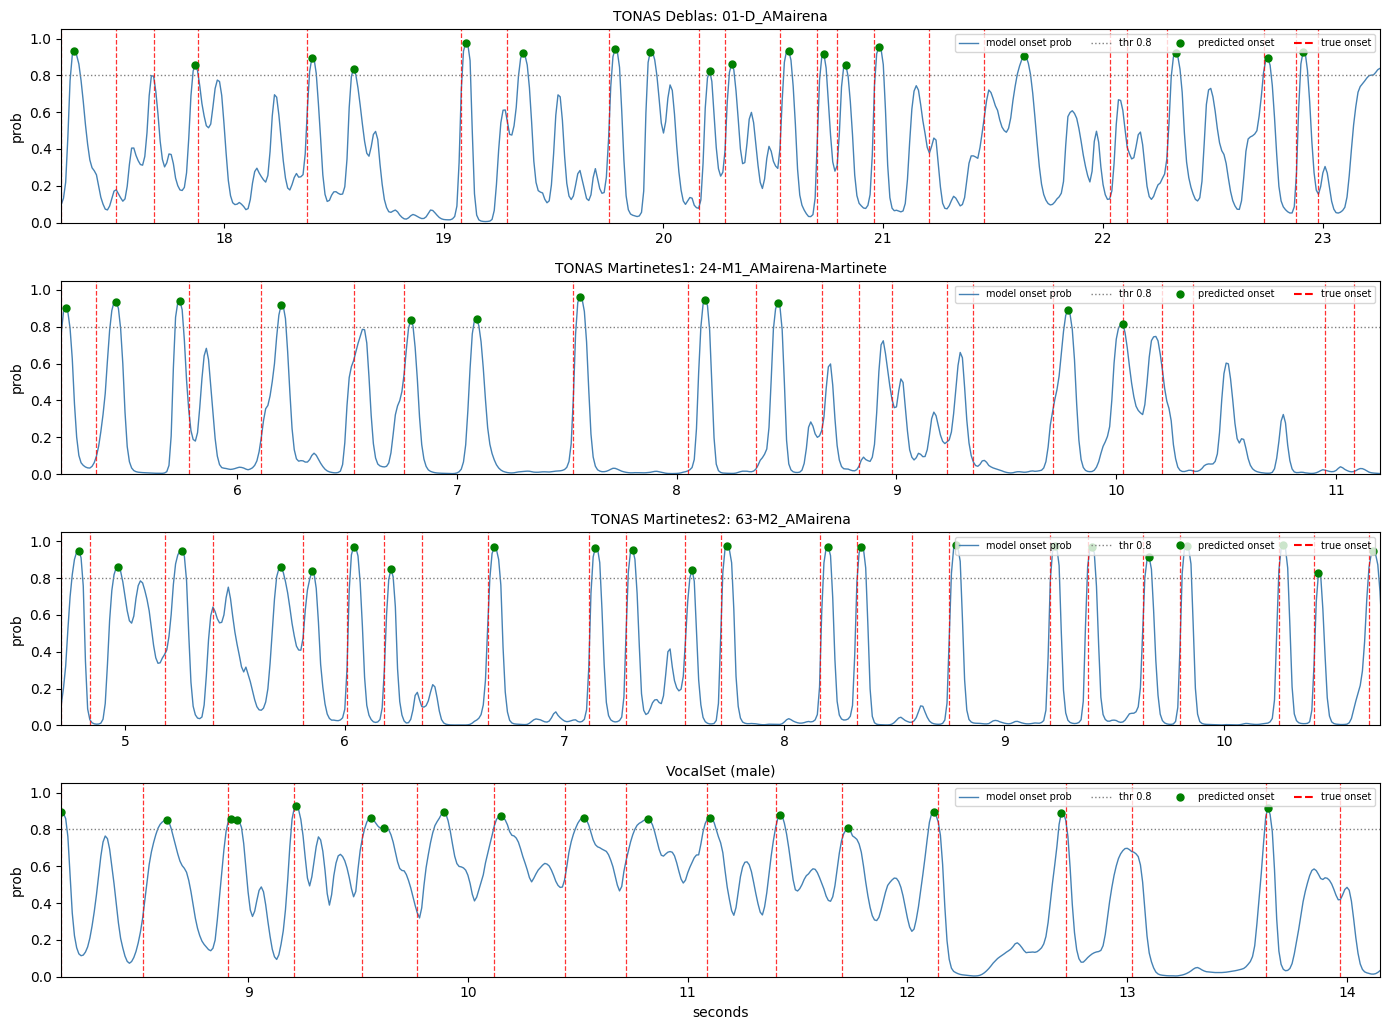

In [7]:
import matplotlib.pyplot as plt

model = OnsetCRNN().to(device)
model.load_state_dict(torch.load(weight_files[0], map_location=device)); model.eval()

def onset_prob(wave):
    with torch.no_grad():
        return torch.sigmoid(model(wave.view(1, 1, -1).to(device))[1])[0].cpu().numpy()

def busiest_window(frames, length=600):       # start frame of the 6 s with the most true onsets
    if len(frames) == 0: return 0
    return int(max(frames, key=lambda f: np.sum((frames >= f) & (frames < f + length))))

# pick clips: first clip of each TONAS style + one VocalSet male clip
picks = []
for style in ["Deblas", "Martinetes1", "Martinetes2"]:
    i = next(i for i, c in enumerate(tonas) if c["style"] == style)
    picks.append((f"TONAS {style}: {tonas[i]['name']}", tonas[i]["wave"], true_on[i]))
j = next(j for j, c in enumerate(vs_test) if c["sex"] == "male" and len(c["on_frames"]) > 8)
picks.append(("VocalSet (male)", vs_test[j]["wave"], vs_true[j]))

fig, axes = plt.subplots(len(picks), 1, figsize=(14, 2.6 * len(picks)))
for ax, (title, wave, t_frames) in zip(axes, picks):
    prob  = onset_prob(wave)
    s     = busiest_window(np.asarray(t_frames))
    e     = s + 600
    x     = np.arange(len(prob)) / 100.0
    peaks = sorted(pick_peaks(prob, 0.8))
    ax.plot(x, prob, color="steelblue", lw=1, label="model onset prob")
    ax.axhline(0.8, color="gray", ls=":", lw=1, label="thr 0.8")
    for f in t_frames:
        if s <= f < e: ax.axvline(f / 100, color="red", ls="--", lw=0.9, alpha=0.8)
    ax.plot([p / 100 for p in peaks if s <= p < e], [prob[p] for p in peaks if s <= p < e],
            "o", color="green", ms=5, label="predicted onset")
    ax.plot([], [], color="red", ls="--", label="true onset")
    ax.set_xlim(s / 100, e / 100); ax.set_ylim(0, 1.05)
    ax.set_title(title, fontsize=10); ax.set_ylabel("prob")
    ax.legend(loc="upper right", fontsize=7, ncol=4)
axes[-1].set_xlabel("seconds")
plt.tight_layout(); plt.show()
del model; torch.cuda.empty_cache()





In [8]:
# ===== per-onset info: note duration + gap before it (TONAS and VocalSet) =====
def dur_bin(d):  return "short <0.2s" if d < 0.2 else ("mid 0.2-0.4s" if d < 0.4 else "long >0.4s")
def gap_bin(g):  return ("back-to-back <30ms" if g < 0.03 else
                         "small break 30-150ms" if g < 0.15 else "after rest >150ms")

records = []   # one row per true onset: dataset, file index, frame, dur_bin, gap_bin

for i, c in enumerate(tonas):
    on, off = c["onsets"], c["offsets"]
    for k in range(len(on)):
        gap = np.inf if k == 0 else on[k] - off[k-1]
        records.append(("TONAS", i, int(on[k] / HOP_SECONDS), dur_bin(off[k] - on[k]), gap_bin(gap)))

# VocalSet: rebuild the same file order as vs_test (sorted wavs, test singers, clean files)
vs_files = []
for wav in sorted(V_AUDIO.rglob("*.wav")):
    singer = wav.parts[wav.parts.index("audio") + 1]
    if singer in TEST_SINGERS and wav.stem in csv_lookup:
        vs_files.append(csv_lookup[wav.stem])
assert len(vs_files) == len(vs_test), "file order mismatch"

for i, csv in enumerate(vs_files):
    snd = read_annot(csv); snd = snd[snd["Type"] == "Sound"].sort_values("Start")
    nfr = 1 + vs_test[i]["wave"].shape[0] // HOP
    prev_end = None
    for s, e in zip(snd["Start"], snd["End"]):
        gap = np.inf if prev_end is None else s - prev_end
        f = int(s / HOP_SECONDS)
        if f < nfr:
            records.append(("VocalSet", i, f, dur_bin(e - s), gap_bin(gap)))
        prev_end = e

R = pd.DataFrame(records, columns=["ds", "file", "frame", "dur", "gap"])

# ===== model hits (±50 ms, thr 0.8) for each seed =====
hit_cols = []
for w in weight_files:
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(w, map_location=device)); model.eval()
    peaks = {}
    with torch.no_grad():
        for i, c in enumerate(tonas):
            peaks[("TONAS", i)] = np.array(sorted(pick_peaks(
                torch.sigmoid(model(c["wave"].view(1,1,-1).to(device))[1])[0].cpu().numpy(), 0.8)))
        for i, c in enumerate(vs_test):
            peaks[("VocalSet", i)] = np.array(sorted(pick_peaks(
                torch.sigmoid(model(c["wave"].view(1,1,-1).to(device))[1])[0].cpu().numpy(), 0.8)))
    col = f"hit_{w.stem[-1]}"
    R[col] = [len(peaks[(ds, fi)]) > 0 and np.min(np.abs(peaks[(ds, fi)] - fr)) <= 5
              for ds, fi, fr in zip(R.ds, R.file, R.frame)]
    hit_cols.append(col)
    del model; torch.cuda.empty_cache()
R["recall"] = R[hit_cols].mean(axis=1)

# ===== results =====
for key in ["dur", "gap"]:
    print(f"\n=== recall by {'NOTE LENGTH' if key=='dur' else 'GAP BEFORE NOTE'} (±50 ms, thr 0.8, mean of 3 seeds) ===")
    t = R.groupby(["ds", key]).agg(share=("recall", "size"), recall=("recall", "mean")).reset_index()
    t["share"] = t.groupby("ds")["share"].transform(lambda s: s / s.sum())
    t = t.pivot(index=key, columns="ds", values=["share", "recall"])
    print((t * 100).round(0).astype(int).astype(str).add("%").to_string())


=== recall by NOTE LENGTH (±50 ms, thr 0.8, mean of 3 seeds) ===
             share          recall         
ds           TONAS VocalSet  TONAS VocalSet
dur                                        
long >0.4s     18%      60%    44%      95%
mid 0.2-0.4s   37%      19%    39%      91%
short <0.2s    45%      21%    33%      93%

=== recall by GAP BEFORE NOTE (±50 ms, thr 0.8, mean of 3 seeds) ===
                     share          recall         
ds                   TONAS VocalSet  TONAS VocalSet
gap                                                
after rest >150ms       8%      14%    48%      96%
back-to-back <30ms     71%      86%    34%      93%
small break 30-150ms   20%       1%    42%     100%


In [9]:
# ===== 1) typical singing loudness per file (ignore silence) =====
def active_level(wave):
    db_ = loudness_db(wave)
    return db_[db_ > db_.max() - 30].mean()     # mean dB of frames within 30 dB of the loudest

vs_lvl    = np.array([active_level(c["wave"]) for c in vs_test])
tonas_lvl = np.array([active_level(c["wave"]) for c in tonas])
vs_med = np.median(vs_lvl)
print("=== active singing level (dBFS) per file ===")
print(f"VocalSet: median {vs_med:6.1f} | 10-90%: {np.percentile(vs_lvl,10):6.1f} .. {np.percentile(vs_lvl,90):6.1f}")
print(f"TONAS   : median {np.median(tonas_lvl):6.1f} | 10-90%: {np.percentile(tonas_lvl,10):6.1f} .. {np.percentile(tonas_lvl,90):6.1f}")
print(f"difference (VocalSet - TONAS): {vs_med - np.median(tonas_lvl):+.1f} dB   "
      f"(training gain augmentation only covered about ±3 dB)")

# ===== 2) rescale TONAS and re-score =====
def gain(wave, db): return wave * (10 ** (db / 20))
global_shift = vs_med - np.median(tonas_lvl)
versions = {
    "original":         [c["wave"] for c in tonas],
    "global shift":     [gain(c["wave"], global_shift) for c in tonas],
    "per-file match":   [gain(c["wave"], vs_med - lv) for c, lv in zip(tonas, tonas_lvl)],
}

rows = []
for w in weight_files:
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(w, map_location=device)); model.eval()
    for vname, waves in versions.items():
        with torch.no_grad():
            probs = [torch.sigmoid(model(x.view(1,1,-1).to(device))[1])[0].cpu().numpy() for x in waves]
        _, r50, f50 = event_f1(probs, true_on, 0.8, tol=5)
        _, _,   f20 = event_f1(probs, true_on, 0.8, tol=2)
        rows.append({"seed": w.stem[-1], "version": vname, "F1_±20ms": f20, "F1_±50ms": f50, "recall_±50ms": r50})
    del model; torch.cuda.empty_cache()

res = pd.DataFrame(rows)
print("\n=== TONAS after volume matching (thr 0.8, mean ± std over 3 seeds) ===")
for vname in versions:
    sub = res[res.version == vname]
    print(f"{vname:15s} | " + " | ".join(f"{k} {sub[k].mean():.3f} ± {sub[k].std(ddof=1):.3f}"
                                          for k in ["F1_±20ms", "F1_±50ms", "recall_±50ms"]))

=== active singing level (dBFS) per file ===
VocalSet: median  -34.5 | 10-90%:  -45.1 ..  -27.8
TONAS   : median  -19.6 | 10-90%:  -24.2 ..  -15.8
difference (VocalSet - TONAS): -15.0 dB   (training gain augmentation only covered about ±3 dB)

=== TONAS after volume matching (thr 0.8, mean ± std over 3 seeds) ===
original        | F1_±20ms 0.145 ± 0.038 | F1_±50ms 0.409 ± 0.043 | recall_±50ms 0.367 ± 0.078
global shift    | F1_±20ms 0.166 ± 0.036 | F1_±50ms 0.436 ± 0.040 | recall_±50ms 0.372 ± 0.052
per-file match  | F1_±20ms 0.166 ± 0.039 | F1_±50ms 0.434 ± 0.039 | recall_±50ms 0.371 ± 0.053


In [10]:
import random
import torch.optim as optim

# ===== 1) split TONAS by clip: half test, half training pool (balanced by style) =====
rng = random.Random(0)
by_style = {}
for i, c in enumerate(tonas):
    by_style.setdefault(c["style"], []).append(i)
test_idx, pool_idx = [], []
for style, idxs in by_style.items():
    idxs = idxs[:]; rng.shuffle(idxs)
    k = len(idxs) // 2
    test_idx += idxs[:k]; pool_idx += idxs[k:]
rng.shuffle(pool_idx)                      # first N of this list = the N training clips
print("test clips:", len(test_idx), "| training pool:", len(pool_idx))

# ===== 2) training targets for every TONAS clip (same design as VocalSet training) =====
SOFT_WIDTH = 2
def tonas_targets(c):
    nfr = 1 + c["wave"].shape[0] // HOP
    st  = np.zeros(nfr, np.int64)
    on_t, off_t = np.zeros(nfr, np.float32), np.zeros(nfr, np.float32)
    def bump(arr, center):
        for d in range(-SOFT_WIDTH, SOFT_WIDTH + 1):
            j = center + d
            if 0 <= j < nfr:
                arr[j] = max(arr[j], np.exp(-(d*d) / (2 * (SOFT_WIDTH/2)**2)))
    for a, b in zip(c["onsets"], c["offsets"]):
        fa, fb = int(a / HOP_SECONDS), int(b / HOP_SECONDS)
        st[fa:fb] = 1; bump(on_t, fa); bump(off_t, fb)
    return torch.tensor(st), torch.tensor(on_t), torch.tensor(off_t)
targets = [tonas_targets(c) for c in tonas]

# ===== 3) fine-tune from saved weights =====
def finetune(wpath, train_idx, epochs=15, lr=1e-4, crop=1500, seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(wpath, map_location=device))
    if not train_idx:
        return model                                   # N = 0 -> no training
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    ce  = nn.CrossEntropyLoss()
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(20.0, device=device))
    for ep in range(epochs):
        model.train()
        for i in random.sample(train_idx, len(train_idx)):
            st, on, off = targets[i]
            nfr = len(st)
            s = np.random.randint(0, max(1, nfr - crop)); e = min(nfr, s + crop)   # random 15 s crop
            x = tonas[i]["wave"][s*HOP : e*HOP].view(1, 1, -1).to(device)
            ps, po, pf = model(x)
            F = min(ps.shape[1], e - s)
            loss = (ce(ps[0, :F], st[s:s+F].to(device))
                    + bce(po[0, :F], on[s:s+F].to(device))
                    + bce(pf[0, :F], off[s:s+F].to(device)))
            opt.zero_grad(); loss.backward(); opt.step()
    return model

def score(model, idx):
    model.eval()
    with torch.no_grad():
        probs = [torch.sigmoid(model(tonas[i]["wave"].view(1,1,-1).to(device))[1])[0].cpu().numpy()
                 for i in idx]
    t = [true_on[i] for i in idx]
    return event_f1(probs, t, 0.8, tol=2)[2], event_f1(probs, t, 0.8, tol=5)[2]

# ===== 4) run: N training clips x 3 saved weights =====
rows = []
for N in [0, 5, 10, 20, len(pool_idx)]:
    for k, w in enumerate(weight_files):
        model = finetune(w, pool_idx[:N], seed=k)
        f20, f50 = score(model, test_idx)
        rows.append({"N_clips": N, "seed": k, "F1_±20ms": f20, "F1_±50ms": f50})
        print(f"N={N:2d} seed {k} | F1 ±20ms {f20:.3f} | ±50ms {f50:.3f}")
        del model; torch.cuda.empty_cache()

ft = pd.DataFrame(rows)
print("\n=== TONAS test set (36 unseen clips) after fine-tuning on N TONAS clips (mean ± std, 3 seeds) ===")
for N, sub in ft.groupby("N_clips"):
    print(f"N={N:2d} | F1 ±20ms {sub['F1_±20ms'].mean():.3f} ± {sub['F1_±20ms'].std(ddof=1):.3f}"
          f" | F1 ±50ms {sub['F1_±50ms'].mean():.3f} ± {sub['F1_±50ms'].std(ddof=1):.3f}")

test clips: 36 | training pool: 36
N= 0 seed 0 | F1 ±20ms 0.130 | ±50ms 0.424
N= 0 seed 1 | F1 ±20ms 0.112 | ±50ms 0.379
N= 0 seed 2 | F1 ±20ms 0.180 | ±50ms 0.461
N= 5 seed 0 | F1 ±20ms 0.361 | ±50ms 0.624
N= 5 seed 1 | F1 ±20ms 0.387 | ±50ms 0.634
N= 5 seed 2 | F1 ±20ms 0.355 | ±50ms 0.621
N=10 seed 0 | F1 ±20ms 0.416 | ±50ms 0.680
N=10 seed 1 | F1 ±20ms 0.462 | ±50ms 0.700
N=10 seed 2 | F1 ±20ms 0.424 | ±50ms 0.678
N=20 seed 0 | F1 ±20ms 0.475 | ±50ms 0.715
N=20 seed 1 | F1 ±20ms 0.488 | ±50ms 0.730
N=20 seed 2 | F1 ±20ms 0.488 | ±50ms 0.730
N=36 seed 0 | F1 ±20ms 0.510 | ±50ms 0.750
N=36 seed 1 | F1 ±20ms 0.518 | ±50ms 0.745
N=36 seed 2 | F1 ±20ms 0.517 | ±50ms 0.755

=== TONAS test set (36 unseen clips) after fine-tuning on N TONAS clips (mean ± std, 3 seeds) ===
N= 0 | F1 ±20ms 0.140 ± 0.035 | F1 ±50ms 0.421 ± 0.041
N= 5 | F1 ±20ms 0.368 ± 0.017 | F1 ±50ms 0.626 ± 0.007
N=10 | F1 ±20ms 0.434 ± 0.025 | F1 ±50ms 0.686 ± 0.012
N=20 | F1 ±20ms 0.483 ± 0.007 | F1 ±50ms 0.725 ± 0.009
N

In [11]:
def score_vs(model):
    model.eval()
    with torch.no_grad():
        probs = [torch.sigmoid(model(c["wave"].view(1,1,-1).to(device))[1])[0].cpu().numpy()
                 for c in vs_test]
    return event_f1(probs, vs_true, 0.8, tol=2)[2], event_f1(probs, vs_true, 0.8, tol=5)[2]

rows = []
for N in [0, 5, 10, 20, len(pool_idx)]:
    for k, w in enumerate(weight_files):
        model = finetune(w, pool_idx[:N], seed=k)
        t20, t50 = score(model, test_idx)       # TONAS (36 unseen clips)
        v20, v50 = score_vs(model)              # VocalSet (252 test recordings)
        rows.append({"N_clips": N, "seed": k, "TONAS_±20": t20, "TONAS_±50": t50,
                     "VS_±20": v20, "VS_±50": v50})
        print(f"N={N:2d} seed {k} | TONAS {t20:.3f} / {t50:.3f} | VocalSet {v20:.3f} / {v50:.3f}")
        del model; torch.cuda.empty_cache()

ft2 = pd.DataFrame(rows)
print("\n=== after fine-tuning on N TONAS clips (F1, thr 0.8, mean ± std over 3 seeds) ===")
print("        |   TONAS ±20ms   |   TONAS ±50ms   |  VocalSet ±20ms |  VocalSet ±50ms")
for N, sub in ft2.groupby("N_clips"):
    print(f"N={N:2d}    | " + " | ".join(
        f"{sub[k].mean():.3f} ± {sub[k].std(ddof=1):.3f}"
        for k in ["TONAS_±20", "TONAS_±50", "VS_±20", "VS_±50"]))

N= 0 seed 0 | TONAS 0.130 / 0.424 | VocalSet 0.837 / 0.923
N= 0 seed 1 | TONAS 0.112 / 0.379 | VocalSet 0.847 / 0.933
N= 0 seed 2 | TONAS 0.180 / 0.461 | VocalSet 0.819 / 0.921
N= 5 seed 0 | TONAS 0.361 / 0.624 | VocalSet 0.758 / 0.899
N= 5 seed 1 | TONAS 0.387 / 0.634 | VocalSet 0.729 / 0.899
N= 5 seed 2 | TONAS 0.355 / 0.621 | VocalSet 0.761 / 0.881
N=10 seed 0 | TONAS 0.415 / 0.680 | VocalSet 0.722 / 0.879
N=10 seed 1 | TONAS 0.462 / 0.700 | VocalSet 0.703 / 0.879
N=10 seed 2 | TONAS 0.424 / 0.678 | VocalSet 0.724 / 0.856
N=20 seed 0 | TONAS 0.475 / 0.716 | VocalSet 0.626 / 0.839
N=20 seed 1 | TONAS 0.488 / 0.730 | VocalSet 0.645 / 0.854
N=20 seed 2 | TONAS 0.488 / 0.730 | VocalSet 0.632 / 0.808
N=36 seed 0 | TONAS 0.510 / 0.751 | VocalSet 0.523 / 0.791
N=36 seed 1 | TONAS 0.519 / 0.745 | VocalSet 0.574 / 0.817
N=36 seed 2 | TONAS 0.517 / 0.754 | VocalSet 0.618 / 0.806

=== after fine-tuning on N TONAS clips (F1, thr 0.8, mean ± std over 3 seeds) ===
        |   TONAS ±20ms   |   TO

In [12]:
# ===== 1) load ~200 VocalSet TRAINING files (never the test singers female4/male6) =====
cands = [w for w in sorted(V_AUDIO.rglob("*.wav"))
         if w.parts[w.parts.index("audio") + 1] not in TEST_SINGERS and w.stem in csv_lookup]
random.Random(0).shuffle(cands)
vs_train = []
for wav in cands:
    if len(vs_train) >= 200: break
    wf, sr = torchaudio.load(str(wav))
    ann = read_annot(csv_lookup[wav.stem])
    if not len(ann) or abs(ann["End"].max()/(wf.shape[1]/sr) - 1.0) > 0.1:   # same clean filter
        continue
    snd = ann[ann["Type"] == "Sound"]
    vs_train.append({"wave": wf[0], "onsets": snd["Start"].values, "offsets": snd["End"].values})
vs_targets = [tonas_targets(c) for c in vs_train]      # same target builder works for both
print("VocalSet replay files:", len(vs_train))

# ===== 2) fine-tune on TONAS + VocalSet together (1 TONAS clip + 1 VocalSet clip per step) =====
def train_step(model, opt, ce, bce, wave, tg, crop=1500):
    st, on, off = tg
    nfr = len(st)
    s = np.random.randint(0, max(1, nfr - crop)); e = min(nfr, s + crop)
    ps, po, pf = model(wave[s*HOP : e*HOP].view(1, 1, -1).to(device))
    F = min(ps.shape[1], e - s)
    loss = (ce(ps[0, :F], st[s:s+F].to(device))
            + bce(po[0, :F], on[s:s+F].to(device))
            + bce(pf[0, :F], off[s:s+F].to(device)))
    opt.zero_grad(); loss.backward(); opt.step()

def finetune_mix(wpath, train_idx, epochs=15, lr=1e-4, seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(wpath, map_location=device))
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    ce  = nn.CrossEntropyLoss()
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(20.0, device=device))
    for ep in range(epochs):
        model.train()
        for i in random.sample(train_idx, len(train_idx)):
            train_step(model, opt, ce, bce, tonas[i]["wave"], targets[i])        # TONAS clip
            j = random.randrange(len(vs_train))
            train_step(model, opt, ce, bce, vs_train[j]["wave"], vs_targets[j])  # VocalSet clip
    return model

# ===== 3) run and compare with TONAS-only fine-tuning =====
rows = []
for N in [5, len(pool_idx)]:
    for k, w in enumerate(weight_files):
        model = finetune_mix(w, pool_idx[:N], seed=k)
        t20, t50 = score(model, test_idx)
        v20, v50 = score_vs(model)
        rows.append({"N_clips": N, "seed": k, "TONAS_±20": t20, "TONAS_±50": t50,
                     "VS_±20": v20, "VS_±50": v50})
        print(f"[mix] N={N:2d} seed {k} | TONAS {t20:.3f} / {t50:.3f} | VocalSet {v20:.3f} / {v50:.3f}")
        del model; torch.cuda.empty_cache()

mix = pd.DataFrame(rows)
cols = ["TONAS_±20", "TONAS_±50", "VS_±20", "VS_±50"]
print("\n=== fine-tuning: TONAS only vs TONAS + VocalSet (F1, thr 0.8, mean ± std, 3 seeds) ===")
print("                    |   TONAS ±20ms   |   TONAS ±50ms   |  VocalSet ±20ms |  VocalSet ±50ms")
base = ft2[ft2.N_clips == 0]
print("no fine-tune        | " + " | ".join(f"{base[c].mean():.3f} ± {base[c].std(ddof=1):.3f}" for c in cols))
for N in [5, len(pool_idx)]:
    a = ft2[ft2.N_clips == N]; b = mix[mix.N_clips == N]
    print(f"N={N:2d} TONAS only    | " + " | ".join(f"{a[c].mean():.3f} ± {a[c].std(ddof=1):.3f}" for c in cols))
    print(f"N={N:2d} TONAS+VocalSet| " + " | ".join(f"{b[c].mean():.3f} ± {b[c].std(ddof=1):.3f}" for c in cols))

VocalSet replay files: 200
[mix] N= 5 seed 0 | TONAS 0.329 / 0.609 | VocalSet 0.811 / 0.918
[mix] N= 5 seed 1 | TONAS 0.366 / 0.621 | VocalSet 0.809 / 0.921
[mix] N= 5 seed 2 | TONAS 0.351 / 0.612 | VocalSet 0.809 / 0.914
[mix] N=36 seed 0 | TONAS 0.468 / 0.744 | VocalSet 0.810 / 0.916
[mix] N=36 seed 1 | TONAS 0.491 / 0.740 | VocalSet 0.813 / 0.911
[mix] N=36 seed 2 | TONAS 0.495 / 0.751 | VocalSet 0.788 / 0.896

=== fine-tuning: TONAS only vs TONAS + VocalSet (F1, thr 0.8, mean ± std, 3 seeds) ===
                    |   TONAS ±20ms   |   TONAS ±50ms   |  VocalSet ±20ms |  VocalSet ±50ms
no fine-tune        | 0.140 ± 0.035 | 0.421 ± 0.041 | 0.834 ± 0.014 | 0.926 ± 0.006
N= 5 TONAS only    | 0.368 ± 0.017 | 0.626 ± 0.007 | 0.749 ± 0.018 | 0.893 ± 0.010
N= 5 TONAS+VocalSet| 0.349 ± 0.018 | 0.614 ± 0.006 | 0.809 ± 0.001 | 0.918 ± 0.003
N=36 TONAS only    | 0.516 ± 0.005 | 0.750 ± 0.004 | 0.572 ± 0.048 | 0.805 ± 0.013
N=36 TONAS+VocalSet| 0.485 ± 0.014 | 0.745 ± 0.006 | 0.803 ± 0.014 | 0